# 02 — Model comparison

Same 10% sample, folds, preprocessing and tuning budget for every model; main metric: macro-F1.

In [1]:
import sys
sys.path.append('..')
import pandas as pd
pd.set_option('display.precision', 3)
from src.data import RESULTS_DIR
from src import plots

RECOMPUTE = False  # True: recalculate everything instead of loading saved results (~50 min)

In [2]:
if RECOMPUTE:
    from src.data import prototype_data
    from src.models import MODELS, SEARCH_SPACES
    from src.evaluation import random_search, save_search, load_configs, compare_models, summarize
    sample, y, folds = prototype_data()

    # 1. Tuning: 10 random configurations per model, saved to reports/results/
    for name, space in SEARCH_SPACES.items():
        save_search(name, random_search(MODELS[name], space, sample, y, folds))

    # 2. Each model with its best configuration, on the same folds
    configs = {name: (MODELS[name], load_configs(name)[0]) for name in MODELS}
    per_fold, by_source, oof = compare_models(sample, y, folds, configs)
    summarize(per_fold).to_csv(f'{RESULTS_DIR}/cv_comparison.csv', index=False)
    by_source.to_csv(f'{RESULTS_DIR}/cv_by_source.csv', index=False)

    # 3. Ablation: RF and LightGBM with Source replaced by a constant
    no_source = sample.assign(Source='unknown')
    ablation_configs = {name: configs[name] for name in ['random_forest', 'lightgbm']}
    ablation, _, _ = compare_models(no_source, y, folds, ablation_configs)
    ablation = ablation.drop(columns=['fold', 'seconds']).groupby('model').agg(['mean', 'std'])
    ablation.stack(level=0).reset_index(names=['model', 'metric']).to_csv(
        f'{RESULTS_DIR}/cv_without_source.csv', index=False)

summary = pd.read_csv(f'{RESULTS_DIR}/cv_comparison.csv')
cols = ['model', 'macro_f1', 'macro_f1_std', 'balanced_acc', 'qwk',
        'recall_Sev1-2', 'recall_Sev3', 'recall_Sev4']
summary[cols].sort_values('macro_f1', ascending=False)

,model,macro_f1,macro_f1_std,balanced_acc,qwk,recall_Sev1-2,recall_Sev3,recall_Sev4
2,random_forest,0.642,2.853e-03,0.647,0.678,0.927,0.852,0.162
4,lightgbm,0.640,6.169e-03,0.651,0.682,0.921,0.877,0.155
5,lightgbm_ordinal,0.636,8.240e-03,0.640,0.700,0.927,0.876,0.116
3,neural_net,0.581,6.356e-03,0.592,0.589,0.906,0.797,0.072
1,logreg,0.554,3.217e-03,0.569,0.598,0.905,0.798,0.003
0,majority,0.295,1.020e-05,0.333,0.000,1.000,0.000,0.000


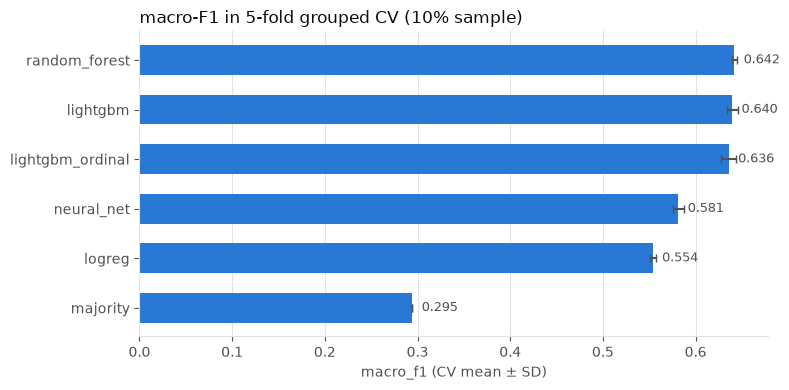

In [3]:
fig = plots.metric_with_error(summary, 'macro_f1', title='macro-F1 in 5-fold grouped CV (10% sample)')

## Results per data source

Within `Source1` all models are much weaker.

In [4]:
by_source = pd.read_csv(f'{RESULTS_DIR}/cv_by_source.csv')
by_source.pivot(index='model', columns='Source', values='macro_f1')

Source,Source1,Source2,Source3
model,,,
lightgbm,0.433,0.572,0.564
lightgbm_ordinal,0.425,0.573,0.564
logreg,0.328,0.522,0.522
majority,0.326,0.249,0.261
neural_net,0.354,0.529,0.526
random_forest,0.390,0.568,0.551


## Without the `Source` feature

In [5]:
ablation = pd.read_csv(f'{RESULTS_DIR}/cv_without_source.csv')
ablation.pivot(index='metric', columns='model', values='mean')

model,lightgbm,random_forest
metric,,
balanced_acc,0.560,0.534
macro_f1,0.531,0.520
qwk,0.475,0.455
recall_Sev1-2,0.809,0.837
recall_Sev3,0.795,0.708
recall_Sev4,0.075,0.057


## Best tuned configurations

In [6]:
for name in ['logreg', 'random_forest', 'neural_net', 'lightgbm', 'lightgbm_ordinal']:
    best = pd.read_csv(f'{RESULTS_DIR}/search_{name}.csv').iloc[0]
    print(f"{name:17s} macro-F1 {best['macro_f1_mean']:.4f}  weight_power={best['weight_power']}")

logreg            macro-F1 0.5538  weight_power=0.5
random_forest     macro-F1 0.6419  weight_power=0.75
neural_net        macro-F1 0.5815  weight_power=0.5
lightgbm          macro-F1 0.6395  weight_power=1.0
lightgbm_ordinal  macro-F1 0.6358  weight_power=1.0
